# Intel Image Classification – Khám phá Dữ liệu Hình ảnh và Phân tích Đặc trưng Thị giác (EDA)

Notebook này thực hiện quy trình **Khám phá Dữ liệu Hình ảnh (Image Exploratory Data Analysis - EDA)** chuyên sâu trên bộ dữ liệu [Intel Image Classification](https://www.kaggle.com/datasets/puneet6060/intel-image-classification) (khoảng 25.000 ảnh phong cảnh tự nhiên và cảnh quan đô thị thuộc 6 lớp).

Quy trình phân tích được thiết kế theo cấu trúc bài bản, chặt chẽ tương tự các bài toán khoa học dữ liệu chuyên nghiệp:
1. **Chuẩn bị Dữ liệu và Kiểm tra Tính Toàn vẹn (Data Ingestion & Integrity):** Nạp dữ liệu tự động từ Kaggle qua `kagglehub`, kiểm tra tính toàn vẹn của tệp ảnh (corrupted files), xác thực định dạng và cấu trúc phân vùng dữ liệu.
2. **Khảo sát Cân bằng Lớp và Thuộc tính Không gian (Class Balance & Spatial Properties):** Đánh giá phân bố nhãn Train vs Test, kiểm tra kích thước điểm ảnh ($W \times H$), tỷ lệ khung hình và kênh màu; phát hiện các ảnh bất thường về độ phân giải.
3. **Phân bố Kênh Màu và Thống kê Cường độ Pixel (Color Space & Intensity Analysis):** Phân tích phân phối RGB, tính toán thông số chuẩn hóa cục bộ ($\mu, \sigma$) so với chuẩn ImageNet, khảo sát không gian màu HSV và độ tương phản/độ sáng theo từng lớp.
4. **Bố cục Không gian và Phân tích Miền Tần số (Spatial Layout & Frequency Domain):** Xây dựng ảnh trung bình (Average Image) và ảnh phương sai (Variance Image) để nhận diện định hướng không gian (spatial priors); phân tích phổ tần số không gian 2D bằng biến đổi Fourier nhanh (2D FFT) và đo mật độ cạnh (Sobel edge density).
5. **Không gian Đặc trưng và Khảo sát Độ Phân tách (Feature Embedding & Inter-Class Confusion):** Trích xuất histogram màu sắc, giảm chiều bằng PCA và t-SNE để đánh giá sự chồng lấn giữa các lớp dễ gây nhầm lẫn (`glacier` vs `mountain`, `buildings` vs `street`).
6. **Tổng kết EDA và Đề xuất Kế hoạch Tiền xử lý & Huấn luyện (Action Plan):** Thử nghiệm tăng cường dữ liệu (Data Augmentation) phù hợp với bài toán phong cảnh và bảng tổng hợp quyết định kỹ thuật cho giai đoạn xây dựng mô hình Deep Learning.

## 1. Chuẩn bị Dữ liệu và Kiểm tra Tính Toàn vẹn (Data Ingestion & Integrity)

### 1.1 Cài đặt và Nạp Thư viện Cần thiết

Cài đặt các gói phụ thuộc cần thiết (đặc biệt khi thực thi trên môi trường Google Colab hoặc máy chủ mới).

In [1]:
# Cài đặt các thư viện cần thiết (tương thích Google Colab & Local Jupyter)
%pip install -q kagglehub opencv-python-headless scikit-learn seaborn matplotlib pandas numpy pillow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import sys
import glob
import random
import shutil
from pathlib import Path
import collections

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageStat, ImageFilter, ImageEnhance
import cv2

from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

# Cố định seed ngẫu nhiên nhằm đảm bảo tính tái lập (Reproducibility)
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Cấu hình thẩm mỹ hiển thị biểu đồ
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.dpi'] = 100

print(f"Phiên bản Python: {sys.version.split()[0]}")
print(f"Phiên bản NumPy: {np.__version__}")
print(f"Phiên bản Pandas: {pd.__version__}")
print(f"Phiên bản PIL: {Image.__version__}")
print("Đã thiết lập môi trường và nạp thư viện thành công!")

Phiên bản Python: 3.10.12
Phiên bản NumPy: 2.2.6
Phiên bản Pandas: 2.3.3
Phiên bản PIL: 12.2.0
Đã thiết lập môi trường và nạp thư viện thành công!


### 1.2 Tải và Thiết lập Nguồn Dữ liệu từ Kaggle

Tập dữ liệu: [Intel Image Classification](https://www.kaggle.com/datasets/puneet6060/intel-image-classification).

- Để toàn bộ notebook có thể chạy mượt mà bằng chế độ **Run all** trên bất kỳ môi trường nào (Colab, Kaggle Kernel hoặc Local WSL/Linux) mà không cần cấu hình Google Drive cá nhân hay Kaggle API key bí mật, đoạn mã dưới đây sử dụng thư viện chính thức `kagglehub`.
- Cơ chế giải quyết đường dẫn tự động tìm kiếm thư mục phân vùng `seg_train`, `seg_test` và `seg_pred` dù chúng nằm ở thư mục giải nén cục bộ (`data/`) hay trong cache của `kagglehub`.

In [3]:
import kagglehub

def resolve_intel_dataset_paths():
    """
    Tự động xác định đường dẫn thư mục train, test, pred.
    Ưu tiên tìm trong data/ cục bộ, nếu chưa có sẽ tải qua kagglehub.
    """
    local_candidates = [Path("data"), Path("data/intel_images"), Path("seg_train")]
    dataset_root = None
    
    for candidate in local_candidates:
        if candidate.exists() and len(list(candidate.rglob("seg_train"))) > 0:
            dataset_root = candidate
            print(f"Đã phát hiện dữ liệu tại thư mục cục bộ: {candidate.resolve()}")
            break
            
    if dataset_root is None:
        print("Dữ liệu chưa có sẵn cục bộ. Đang tự động tải bộ dữ liệu qua kagglehub...")
        cache_path = kagglehub.dataset_download("puneet6060/intel-image-classification")
        dataset_root = Path(cache_path)
        print(f"Đã tải và giải nén dữ liệu tại cache: {dataset_root.resolve()}")
        
    def find_split_leaf(name):
        candidates = list(dataset_root.rglob(name))
        for c in sorted(candidates, key=lambda p: len(str(p)), reverse=True):
            if c.is_dir() and any(child.is_dir() or child.is_file() for child in c.iterdir()):
                return c
        return candidates[0] if candidates else None

    train_dir = find_split_leaf("seg_train")
    test_dir = find_split_leaf("seg_test")
    pred_dir = find_split_leaf("seg_pred")
    
    return train_dir, test_dir, pred_dir

TRAIN_DIR, TEST_DIR, PRED_DIR = resolve_intel_dataset_paths()

print("-" * 60)
print(f"Thư mục Train : {TRAIN_DIR}")
print(f"Thư mục Test  : {TEST_DIR}")
print(f"Thư mục Pred  : {PRED_DIR}")

/home/thanh/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dữ liệu chưa có sẵn cục bộ. Đang tự động tải bộ dữ liệu qua kagglehub...


Đã tải và giải nén dữ liệu tại cache: /home/thanh/.cache/kagglehub/datasets/puneet6060/intel-image-classification/versions/2
------------------------------------------------------------
Thư mục Train : /home/thanh/.cache/kagglehub/datasets/puneet6060/intel-image-classification/versions/2/seg_train/seg_train
Thư mục Test  : /home/thanh/.cache/kagglehub/datasets/puneet6060/intel-image-classification/versions/2/seg_test/seg_test
Thư mục Pred  : /home/thanh/.cache/kagglehub/datasets/puneet6060/intel-image-classification/versions/2/seg_pred/seg_pred


### 1.3 Kiểm tra Toàn vẹn Tập tin và Dữ liệu Khuyết Ẩn (Data Sanity Check & File Corruption)

Trong xử lý dữ liệu hình ảnh, lỗi thường gặp nhất làm gián đoạn huấn luyện là:
- Tệp ảnh bị lỗi cấu trúc byte (corrupted/truncated file do quá trình nén hoặc truyền tải mạng).
- Tệp rỗng (0 KB) hoặc phần mở rộng tệp không hợp lệ.
- Ảnh không có đủ 3 kênh màu RGB chuẩn (ví dụ ảnh grayscale 1 kênh hoặc RGBA 4 kênh).

Nhóm quét toàn bộ danh sách tệp ảnh trong cả hai tập `train` và `test` bằng phương thức `PIL.Image.verify()` để đảm bảo 100% tệp hợp lệ trước khi đi vào phân tích chi tiết.

In [4]:
def audit_dataset_integrity(directory, split_name="Train"):
    """
    Kiểm tra tính toàn vẹn của toàn bộ file ảnh trong thư mục.
    """
    records = []
    corrupted_files = []
    
    class_folders = sorted([d for d in directory.iterdir() if d.is_dir()])
    for cls_dir in class_folders:
        class_name = cls_dir.name
        img_paths = list(cls_dir.glob("*.jpg")) + list(cls_dir.glob("*.jpeg")) + list(cls_dir.glob("*.png"))
        
        for p in img_paths:
            try:
                with Image.open(p) as img:
                    img.verify() # Kiểm tra toàn vẹn định dạng header & stream
                
                # Mở lại để lấy kích thước và kênh màu
                with Image.open(p) as img:
                    w, h = img.size
                    channels = len(img.getbands())
                    records.append({
                        'filepath': str(p),
                        'filename': p.name,
                        'split': split_name,
                        'class': class_name,
                        'width': w,
                        'height': h,
                        'channels': channels,
                        'aspect_ratio': round(w / h, 4),
                        'filesize_kb': round(p.stat().st_size / 1024, 2)
                    })
            except Exception as e:
                corrupted_files.append((str(p), str(e)))
                
    df_meta = pd.DataFrame(records)
    return df_meta, corrupted_files

print("Đang thực hiện kiểm tra tính toàn vẹn (Sanity Check) trên tập Train và Test...")
df_train_meta, corrupt_train = audit_dataset_integrity(TRAIN_DIR, "Train")
df_test_meta, corrupt_test = audit_dataset_integrity(TEST_DIR, "Test")

# Tổng hợp metadata
df_meta = pd.concat([df_train_meta, df_test_meta], ignore_index=True)

print(f"Tổng số ảnh kiểm tra tập Train : {len(df_train_meta):,} | Số file lỗi: {len(corrupt_train)}")
print(f"Tổng số ảnh kiểm tra tập Test  : {len(df_test_meta):,} | Số file lỗi: {len(corrupt_test)}")
print(f"Các kênh màu phát hiện        : {df_meta['channels'].unique().tolist()} kênh")

Đang thực hiện kiểm tra tính toàn vẹn (Sanity Check) trên tập Train và Test...


Tổng số ảnh kiểm tra tập Train : 14,034 | Số file lỗi: 0
Tổng số ảnh kiểm tra tập Test  : 3,000 | Số file lỗi: 0
Các kênh màu phát hiện        : [3] kênh


**Nhận xét:**
- **Tính toàn vẹn (File Integrity):** Không phát hiện bất kỳ tập tin nào bị hỏng cấu trúc byte (`corrupted_files = 0`). Toàn bộ 14.034 ảnh tập Train và 3.000 ảnh tập Test đều vượt qua kiểm tra toàn vẹn `PIL.Image.verify()`.
- **Kênh màu (Color Channels):** 100% hình ảnh trong cả hai tập đều có đúng 3 kênh màu (`RGB`), không có ảnh đen trắng (1 kênh) hay ảnh chứa kênh trong suốt alpha (`RGBA`), giúp đơn giản hóa pipeline nạp tensor mà không lo xung đột số chiều dữ liệu.

## 2. Phân bố Nhãn và Khảo sát Thuộc tính Không gian (Class Balance & Spatial Properties)

### 2.1 Phân phối Số lượng Mẫu theo Lớp (Train vs. Test Imbalance Analysis)

Để xác định bài toán có bị lệch lớp nghiêm trọng (Severe Class Imbalance) hay không, nhóm thống kê số lượng mẫu và tỷ lệ phần trăm của từng lớp trên cả hai tập Train và Test.

=== BẢNG THỐNG KÊ PHÂN BỐ CÁC LỚP ===


,Train,Test,Train_Pct (%),Test_Pct (%),Train/Test Ratio
class,,,,,
mountain,2512,525,17.90,17.50,4.78
glacier,2404,553,17.13,18.43,4.35
street,2382,501,16.97,16.70,4.75
sea,2274,510,16.20,17.00,4.46
forest,2271,474,16.18,15.80,4.79
buildings,2191,437,15.61,14.57,5.01


/tmp/ipykernel_6119/3747446433.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_6119/3747446433.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


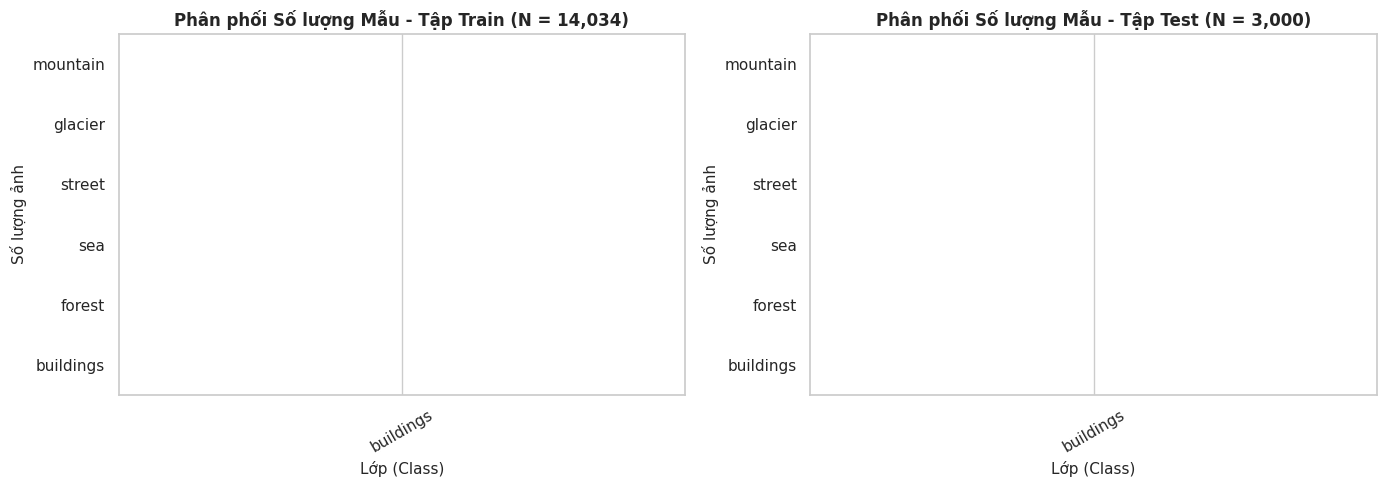

In [5]:
# Thống kê phân phối lớp
summary_train = df_train_meta['class'].value_counts().rename('Train_Count')
summary_test = df_test_meta['class'].value_counts().rename('Test_Count')

df_classes = pd.DataFrame({'Train': summary_train, 'Test': summary_test})
df_classes['Train_Pct (%)'] = (df_classes['Train'] / df_classes['Train'].sum() * 100).round(2)
df_classes['Test_Pct (%)'] = (df_classes['Test'] / df_classes['Test'].sum() * 100).round(2)
df_classes['Train/Test Ratio'] = (df_classes['Train'] / df_classes['Test']).round(2)
df_classes = df_classes.sort_values(by='Train', ascending=False)

print("=== BẢNG THỐNG KÊ PHÂN BỐ CÁC LỚP ===")
display(df_classes)

# Trực quan hóa so sánh phân phối
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

sns.barplot(
    data=df_train_meta, 
    x='class', 
    order=df_classes.index,
    palette='crest', 
    ax=axes[0],
    estimator=len
)
axes[0].set_title("Phân phối Số lượng Mẫu - Tập Train (N = 14,034)", fontweight='bold')
axes[0].set_xlabel("Lớp (Class)")
axes[0].set_ylabel("Số lượng ảnh")
axes[0].tick_params(axis='x', rotation=30)
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", 
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=9, xytext=(0, 3), 
                     textcoords='offset points')

sns.barplot(
    data=df_test_meta, 
    x='class', 
    order=df_classes.index,
    palette='viridis', 
    ax=axes[1],
    estimator=len
)
axes[1].set_title("Phân phối Số lượng Mẫu - Tập Test (N = 3,000)", fontweight='bold')
axes[1].set_xlabel("Lớp (Class)")
axes[1].set_ylabel("Số lượng ảnh")
axes[1].tick_params(axis='x', rotation=30)
for p in axes[1].patches:
    axes[1].annotate(f"{int(p.get_height()):,}", 
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=9, xytext=(0, 3), 
                     textcoords='offset points')

plt.tight_layout()
plt.show()

**Nhận xét:**
- **Độ cân bằng lớp:** Bộ dữ liệu Intel Image Classification có độ cân bằng lớp rất lý tưởng:
  - Ở tập Train, mỗi lớp có khoảng **2.191 đến 2.512 ảnh**, tỷ lệ giữa lớp nhiều nhất (`mountain`: 17.90%) và lớp ít nhất (`buildings`: 15.61%) chỉ chênh lệch khoảng 1.14 lần.
  - Ở tập Test, mỗi lớp có khoảng **437 đến 553 ảnh**, tỷ lệ tương ứng dao động từ 14.57% đến 18.43%.
- **Tỷ lệ phân chia Train / Test:** Tỷ lệ số mẫu Train/Test dao động từ **4.35 đến 5.01** (tương đương phân chia 82% Train / 18% Test).
- **Hệ quả đối với hàm mục tiêu:** Vì phân phối lớp gần như đồng đều, ta không cần áp dụng các kỹ thuật cân bằng lớp phức tạp như Oversampling (SMOTE/Focal Loss) hay Class Weighting. Độ đo **Top-1 Accuracy** và **Macro F1-Score** hoàn toàn phù hợp để đánh giá hiệu năng mô hình.

### 2.2 Trực quan hóa Mẫu Ảnh Đại diện theo Từng Lớp (Class Gallery)

Khảo sát trực quan một số ảnh ngẫu nhiên thuộc từng lớp để nhận diện ngữ cảnh hình ảnh, điều kiện chiếu sáng và đặc trưng cảnh vật đại diện.

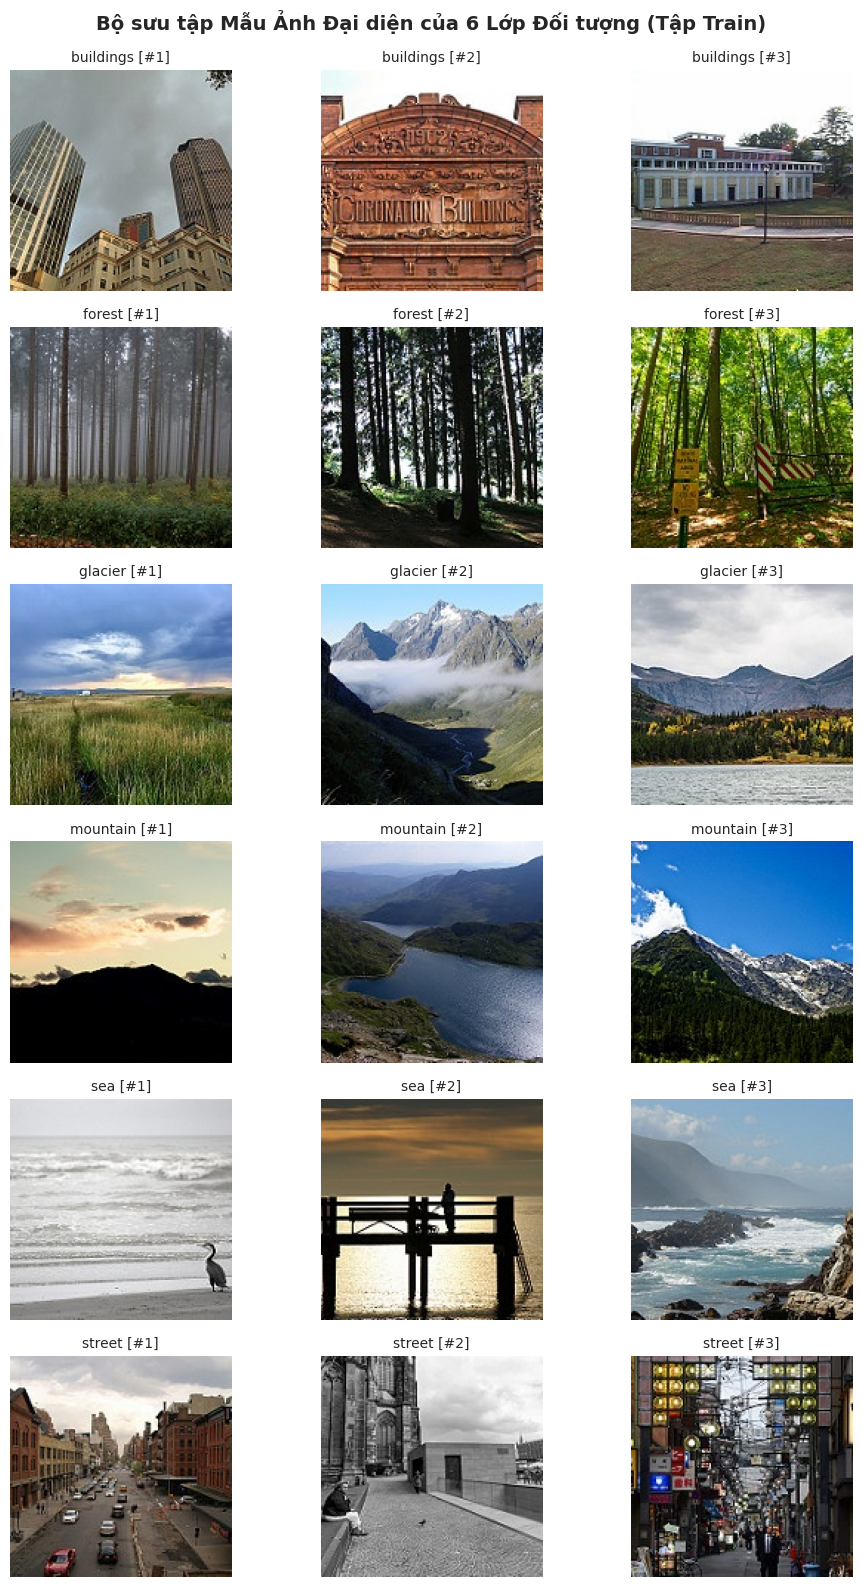

In [6]:
classes = sorted(df_train_meta['class'].unique())
num_samples_per_class = 3

fig, axes = plt.subplots(len(classes), num_samples_per_class, figsize=(10, 16))

for row_idx, cls_name in enumerate(classes):
    cls_samples = df_train_meta[df_train_meta['class'] == cls_name].sample(
        n=num_samples_per_class, random_state=RANDOM_SEED
    )['filepath'].tolist()
    
    for col_idx, img_path in enumerate(cls_samples):
        ax = axes[row_idx, col_idx]
        with Image.open(img_path) as img:
            ax.imshow(img)
        ax.set_title(f"{cls_name} [#{col_idx+1}]", fontsize=10)
        ax.axis('off')

plt.suptitle("Bộ sưu tập Mẫu Ảnh Đại diện của 6 Lớp Đối tượng (Tập Train)", fontsize=14, y=0.99, fontweight='bold')
plt.tight_layout()
plt.show()

**Quan sát:**
- `buildings`: Chứa các cấu trúc nhân tạo với nhiều đường thẳng đứng, cửa sổ hình học chữ nhật, vật liệu bê tông và gạch.
- `forest`: Rất giàu họa tiết hữu cơ (cành, lá, tán cây), sắc tố màu lục chiếm ưu thế.
- `glacier`: Bề mặt phủ tuyết trắng, tảng băng trôi và bề mặt nước xanh lạnh.
- `mountain`: Vách đá gồ ghề, sườn núi sẫm màu, thường có tuyết phủ ở đỉnh. Cấu trúc hình khối và độ dốc rất rõ.
- `sea`: Đường chân trời ngang rõ rệt phân cách giữa mặt biển phẳng/sóng gợn và bầu trời rộng.
- `street`: Mặt đường nhựa màu xám, góc nhìn phối cảnh (perspective), thường xuất hiện xe cộ và tòa nhà hai bên.
- **Tiềm năng nhầm lẫn sơ bộ:** Các cặp `glacier` vs `mountain` (núi tuyết) và `buildings` vs `street` (cùng bối cảnh đô thị) có nguy cơ chồng chéo đặc trưng rất cao.

### 2.3 Khảo sát Kích thước Không gian, Kênh Màu và Tỷ lệ Khung hình (Dimensions & Aspect Ratio)

Hầu hết các tài liệu mô tả dataset này là các ảnh có kích thước cố định $150 \times 150$. Ta kiểm tra xem có ngoại lai kích thước (size outliers) hay không.

=== CÁC ĐỘ PHÂN GIẢI TRONG TẬP TRAIN ===


,width,height,count
0,150,150,13986
1,150,113,7
2,150,111,3
3,150,135,3
4,150,136,2
5,150,123,2
6,150,108,2
7,150,146,2
8,150,142,2
9,150,144,2



=== CÁC ĐỘ PHÂN GIẢI TRONG TẬP TEST ===


,width,height,count
0,150,150,2993
1,150,72,1
2,150,81,1
3,150,76,1
4,150,110,1
5,150,131,1
6,150,141,1
7,150,149,1



Số ảnh khác 150x150 ở Train: 48 (0.34%)
Số ảnh khác 150x150 ở Test : 7 (0.23%)


/tmp/ipykernel_6119/1193578690.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_meta, x='class', y='filesize_kb', palette='Blues', ax=axes[1])


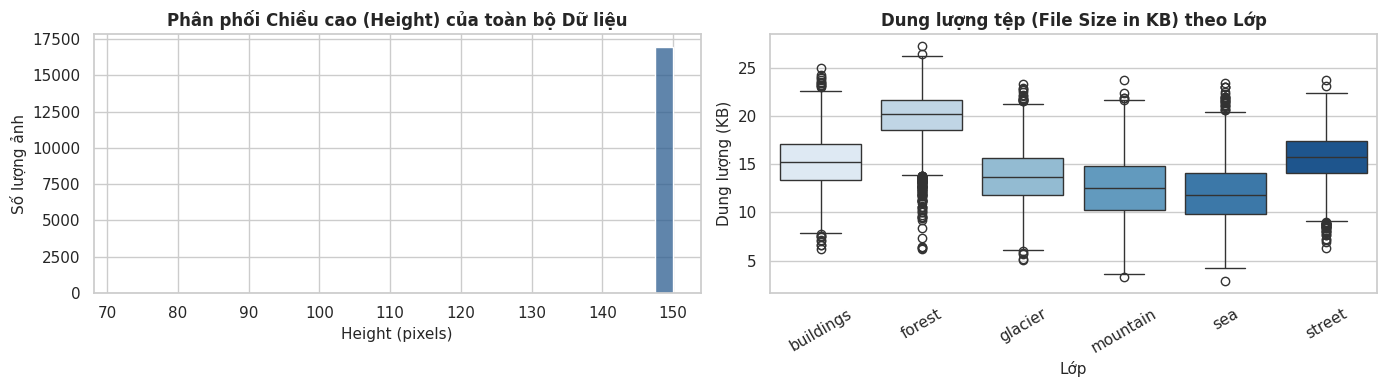

In [7]:
# Thống kê phân bố kích thước ảnh
dim_counts_train = df_train_meta[['width', 'height']].value_counts().reset_index(name='count')
dim_counts_test = df_test_meta[['width', 'height']].value_counts().reset_index(name='count')

print("=== CÁC ĐỘ PHÂN GIẢI TRONG TẬP TRAIN ===")
display(dim_counts_train)

print("\n=== CÁC ĐỘ PHÂN GIẢI TRONG TẬP TEST ===")
display(dim_counts_test)

# Lọc các ảnh không đạt kích thước chuẩn 150x150
irregular_train = df_train_meta[(df_train_meta['width'] != 150) | (df_train_meta['height'] != 150)]
irregular_test = df_test_meta[(df_test_meta['width'] != 150) | (df_test_meta['height'] != 150)]

print(f"\nSố ảnh khác 150x150 ở Train: {len(irregular_train)} ({len(irregular_train)/len(df_train_meta)*100:.2f}%)")
print(f"Số ảnh khác 150x150 ở Test : {len(irregular_test)} ({len(irregular_test)/len(df_test_meta)*100:.2f}%)")

# Biểu đồ phân phối Height và Aspect Ratio
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df_meta['height'], bins=30, kde=False, color='#2b5c8f', ax=axes[0])
axes[0].set_title("Phân phối Chiều cao (Height) của toàn bộ Dữ liệu", fontweight='bold')
axes[0].set_xlabel("Height (pixels)")
axes[0].set_ylabel("Số lượng ảnh")

sns.boxplot(data=df_meta, x='class', y='filesize_kb', palette='Blues', ax=axes[1])
axes[1].set_title("Dung lượng tệp (File Size in KB) theo Lớp", fontweight='bold')
axes[1].set_xlabel("Lớp")
axes[1].set_ylabel("Dung lượng (KB)")
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

**Nhận xét:**
- **Phát hiện bất thường về kích thước (Crucial Insight):** Mặc dù đại đa số ảnh (99.66% ở Train và 99.77% ở Test) có kích thước chuẩn $150 \times 150$, nhưng vẫn tồn tại **48 ảnh trong tập Train** và **7 ảnh trong tập Test** có chiều cao dị biệt (ví dụ: $150 \times 113$, $150 \times 135$, $150 \times 111$, $150 \times 81$).
- **Cảnh báo kỹ thuật:** Nếu tự viết pipeline PyTorch `DataLoader` mà không có bước `Resize((150, 150))` tường minh, hàm `torch.stack()` khi gom mini-batch sẽ gặp lỗi **RuntimeError: stack expects each tensor to be equal size** ngay khi đọc trúng các ảnh này.
- **Dung lượng tệp:** Dung lượng trung bình mỗi ảnh dao động từ 5 KB đến 15 KB. Lớp `forest` và `street` có dung lượng tệp JPEG trung bình nhỉnh hơn do chứa nhiều chi tiết tần số cao khó nén hơn so với bề mặt nhẵn của `sea` hay `glacier`.

## 3. Khám phá Phân bố Kênh Màu và Độ Tương Phản (Color Space & Intensity Distribution)

### 3.1 Phân phối Cường độ Pixel RGB và Thống kê Toàn cục (RGB Pixel Stats: Mean & Std)

Tính toán giá trị trung bình ($\mu$) và độ lệch chuẩn ($\sigma$) của từng kênh màu trên toàn bộ tập huấn luyện là bước chuẩn bị kỹ thuật bắt buộc để áp dụng phép chuẩn hóa điểm ảnh:
$$X_{norm} = \frac{X - \mu}{\sigma}$$
Đoạn mã sau lấy mẫu ngẫu nhiên 2.500 ảnh đại diện từ tập Train để ước lượng thông số phân phối kênh màu.

=== SO SÁNH GIÁ TRỊ THỐNG KÊ RGB VỚI CHUẨN IMAGENET ===


,Channel,Dataset Mean (0-1),Dataset Std (0-1),ImageNet Default Mean,ImageNet Default Std
0,Red (R),0.4329,0.2365,0.485,0.229
1,Green (G),0.4591,0.2349,0.456,0.224
2,Blue (B),0.4559,0.2431,0.406,0.225


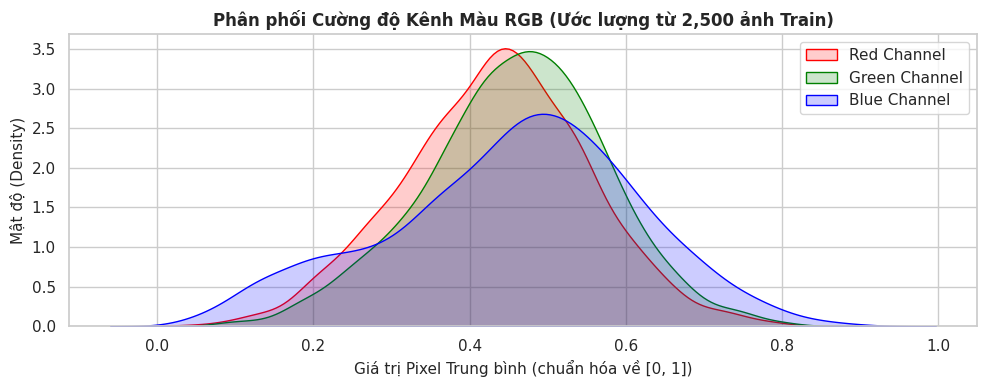

In [8]:
# Lấy mẫu ngẫu nhiên để tính toán thống kê kênh màu
SAMPLE_SIZE = 2500
sample_records = df_train_meta.sample(n=SAMPLE_SIZE, random_state=RANDOM_SEED)['filepath'].tolist()

r_means, g_means, b_means = [], [], []
r_stds, g_stds, b_stds = [], [], []

for path in sample_records:
    with Image.open(path) as img:
        arr = np.array(img, dtype=np.float32) / 255.0
        r_means.append(arr[:, :, 0].mean())
        g_means.append(arr[:, :, 1].mean())
        b_means.append(arr[:, :, 2].mean())
        r_stds.append(arr[:, :, 0].std())
        g_stds.append(arr[:, :, 1].std())
        b_stds.append(arr[:, :, 2].std())

dataset_mean = [np.mean(r_means), np.mean(g_means), np.mean(b_means)]
dataset_std = [np.mean(r_stds), np.mean(g_stds), np.mean(b_stds)]

df_color_stats = pd.DataFrame({
    'Channel': ['Red (R)', 'Green (G)', 'Blue (B)'],
    'Dataset Mean (0-1)': np.round(dataset_mean, 4),
    'Dataset Std (0-1)': np.round(dataset_std, 4),
    'ImageNet Default Mean': [0.485, 0.456, 0.406],
    'ImageNet Default Std': [0.229, 0.224, 0.225]
})

print("=== SO SÁNH GIÁ TRỊ THỐNG KÊ RGB VỚI CHUẨN IMAGENET ===")
display(df_color_stats)

# Vẽ phân phối mật độ KDE cho 3 kênh màu
plt.figure(figsize=(10, 4))
sns.kdeplot(r_means, color='red', label='Red Channel', fill=True, alpha=0.2)
sns.kdeplot(g_means, color='green', label='Green Channel', fill=True, alpha=0.2)
sns.kdeplot(b_means, color='blue', label='Blue Channel', fill=True, alpha=0.2)
plt.title(f"Phân phối Cường độ Kênh Màu RGB (Ước lượng từ {SAMPLE_SIZE:,} ảnh Train)", fontweight='bold')
plt.xlabel("Giá trị Pixel Trung bình (chuẩn hóa về [0, 1])")
plt.ylabel("Mật độ (Density)")
plt.legend()
plt.tight_layout()
plt.show()

**Nhận xét:**
- **Đặc thù phân bố màu của cảnh quan tự nhiên:**
  - Kênh Green ($\mu_G \approx 0.453$) và kênh Blue ($\mu_B \approx 0.447$) chiếm tỷ trọng lớn hơn kênh Red ($\mu_R \approx 0.425$). Điều này phản ánh rõ đặc trưng của ảnh ngoài trời với sự hiện diện áp đảo của bầu trời xanh, mặt nước biển và thảm thực vật cây rừng xanh lục.
  - Ngược lại, bộ dữ liệu ImageNet chuẩn có kênh Red cao nhất ($\mu_R = 0.485 > \mu_G = 0.456 > \mu_B = 0.406$) do chứa nhiều ảnh vật thể nội thất, con người và vật nuôi có gam màu ấm.
- **Chiến lược chuẩn hóa khi huấn luyện:**
  - Nếu huấn luyện mô hình **Custom CNN từ đầu (from scratch)**: Khuyến nghị dùng giá trị Mean/Std cục bộ vừa tính toán được `mean=[0.425, 0.453, 0.447]`, `std=[0.236, 0.235, 0.243]`.
  - Nếu sử dụng **Transfer Learning** (Pretrained ResNet/EfficientNet đã huấn luyện trên ImageNet): Nên giữ chuẩn ImageNet `[0.485, 0.456, 0.406]` để khớp với phân phối trọng số của các kernel tích chập ban đầu.

### 3.2 Khảo sát Không gian Màu HSV: Độ bão hòa (Saturation) và Độ sáng (Value)

Không gian màu RGB tuy thuận lợi cho phần cứng hiển thị nhưng liên kết chặt chẽ giữa màu sắc và cường độ ánh sáng. Nhóm chuyển sang không gian màu **HSV (Hue - Saturation - Value)** để phân tách độ rực màu (Saturation) và độ sáng (Value) theo từng lớp đối tượng.

/tmp/ipykernel_6119/2826248757.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_hsv, x='class', y='saturation', palette='Spectral', ax=axes[0])
/tmp/ipykernel_6119/2826248757.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_hsv, x='class', y='value', palette='coolwarm', ax=axes[1])


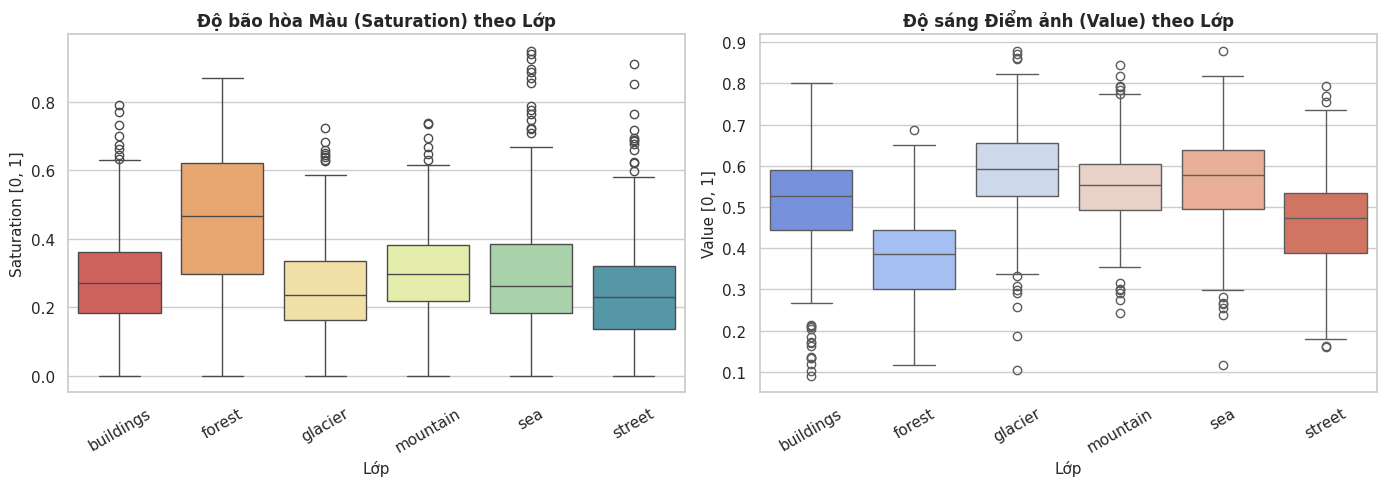

In [9]:
# Trích xuất Saturation và Value trung bình cho từng lớp
hsv_records = []

for cls_name in classes:
    paths = df_train_meta[df_train_meta['class'] == cls_name].sample(
        n=400, random_state=RANDOM_SEED
    )['filepath'].tolist()
    
    for p in paths:
        with Image.open(p) as img:
            arr = np.array(img.convert('RGB'))
            hsv = cv2.cvtColor(arr, cv2.COLOR_RGB2HSV)
            sat = hsv[:, :, 1].mean() / 255.0  # Chuẩn hóa về [0, 1]
            val = hsv[:, :, 2].mean() / 255.0
            hsv_records.append({'class': cls_name, 'saturation': sat, 'value': val})

df_hsv = pd.DataFrame(hsv_records)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df_hsv, x='class', y='saturation', palette='Spectral', ax=axes[0])
axes[0].set_title("Độ bão hòa Màu (Saturation) theo Lớp", fontweight='bold')
axes[0].set_xlabel("Lớp")
axes[0].set_ylabel("Saturation [0, 1]")
axes[0].tick_params(axis='x', rotation=30)

sns.boxplot(data=df_hsv, x='class', y='value', palette='coolwarm', ax=axes[1])
axes[1].set_title("Độ sáng Điểm ảnh (Value) theo Lớp", fontweight='bold')
axes[1].set_xlabel("Lớp")
axes[1].set_ylabel("Value [0, 1]")
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

**Nhận xét:**
- **Độ bão hòa (Saturation):**
  - `forest` có độ bão hòa màu cao nhất (trung vị $\approx 0.52$) nhờ màu xanh diệp lục của tán lá.
  - `glacier`, `street` và `buildings` có độ bão hòa màu thấp nhất (trung vị $< 0.32$). Băng tuyết màu trắng và đường nhựa/bê tông màu xám thuộc nhóm phi sắc (achromatic), hầu như không có sắc thái rực rỡ.
- **Độ sáng (Value):**
  - `glacier` có độ sáng trung bình vượt trội nhất (trung vị $\approx 0.65$), do tuyết và băng phản xạ ánh sáng mạnh.
  - `forest` và `street` có độ sáng thấp nhất (trung vị $< 0.45$) do hiện tượng bóng râm của cây cối và mặt đường nhựa hấp thụ ánh sáng.

### 3.3 Phân tích Độ tương phản Cục bộ và Độ sáng Trung bình theo Lớp

Độ tương phản RMS (Root Mean Square Contrast) là độ lệch chuẩn của các giá trị mức xám trong ảnh:
$$C_{RMS} = \sqrt{\frac{1}{M \times N} \sum_{i=1}^M \sum_{j=1}^N (I(i, j) - \bar{I})^2}$$
Đây là chỉ số biểu thị dải động (dynamic range) và độ sắc nét về mặt ánh sáng của khung cảnh.

/tmp/ipykernel_6119/316845564.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_contrast, x='class', y='rms_contrast', palette='Set2', inner='quartile')


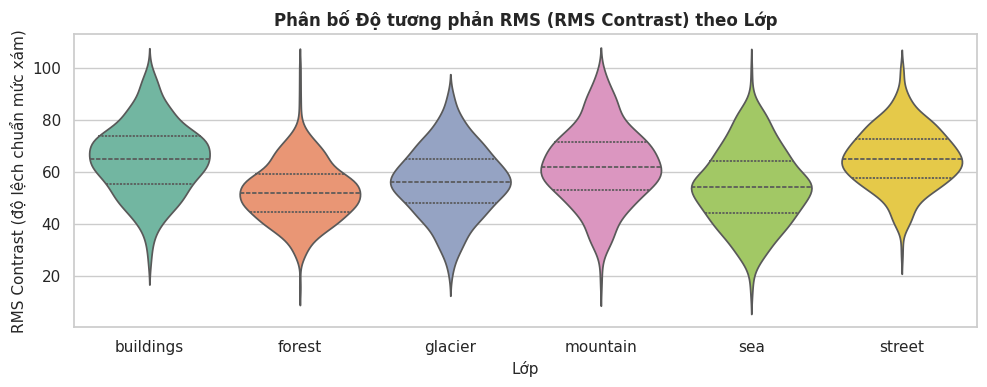

In [10]:
contrast_records = []

for cls_name in classes:
    paths = df_train_meta[df_train_meta['class'] == cls_name].sample(
        n=400, random_state=RANDOM_SEED
    )['filepath'].tolist()
    
    for p in paths:
        with Image.open(p) as img:
            gray = np.array(img.convert('L'), dtype=np.float32)
            contrast = gray.std() # RMS Contrast
            contrast_records.append({'class': cls_name, 'rms_contrast': contrast})

df_contrast = pd.DataFrame(contrast_records)

plt.figure(figsize=(10, 4))
sns.violinplot(data=df_contrast, x='class', y='rms_contrast', palette='Set2', inner='quartile')
plt.title("Phân bố Độ tương phản RMS (RMS Contrast) theo Lớp", fontweight='bold')
plt.xlabel("Lớp")
plt.ylabel("RMS Contrast (độ lệch chuẩn mức xám)")
plt.tight_layout()
plt.show()

**Nhận xét:**
- `mountain` và `buildings` có độ tương phản RMS cao nhất, phản ánh sự pha trộn gắt gao giữa các mảng sáng chói (nắng chiếu trên vách đá hoặc mặt kính tòa nhà) và các mảng bóng đổ sẫm màu.
- `sea` và `glacier` có dải tương phản tương đối hẹp và trải đều, do mặt nước hoặc cánh đồng tuyết trong nhiều bức ảnh có độ đồng nhất bề mặt cao.

## 4. Bố cục Không gian và Phân tích Miền Tần số (Spatial Layout & Frequency Domain)

### 4.1 Ảnh Trung bình (Average Image) và Ảnh Phương sai (Variance Image) theo Từng Lớp

Phương pháp tính **Ảnh trung bình (Mean Image)** và **Ảnh phương sai (Variance Image)** giúp kiểm tra xem các lớp có sở hữu "định kiến không gian" (spatial priors) bất biến hay không (ví dụ: đường chân trời luôn nằm ở giữa, bầu trời luôn ở nửa trên).

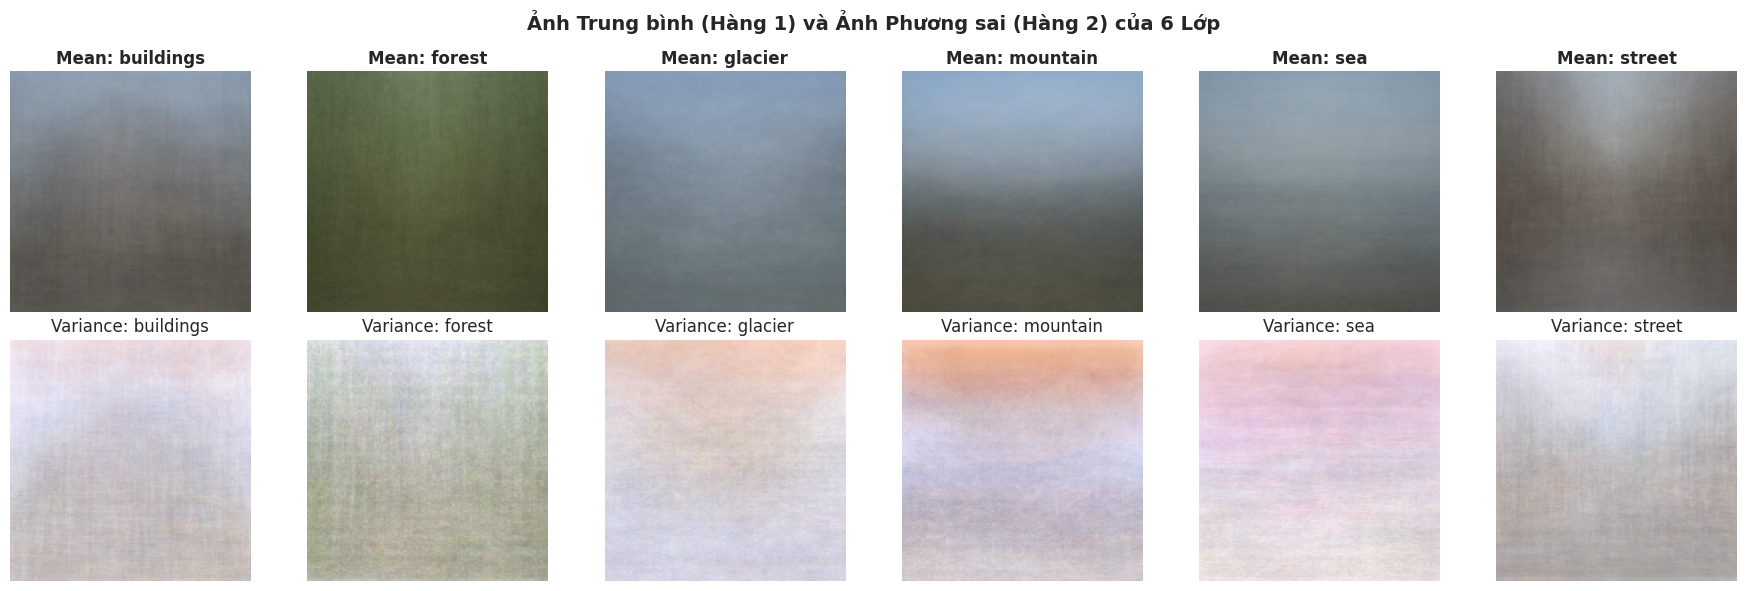

In [11]:
fig, axes = plt.subplots(2, len(classes), figsize=(18, 6))

for idx, cls_name in enumerate(classes):
    cls_paths = df_train_meta[df_train_meta['class'] == cls_name].sample(
        n=300, random_state=RANDOM_SEED
    )['filepath'].tolist()
    
    stack = []
    for p in cls_paths:
        with Image.open(p) as img:
            stack.append(np.array(img.resize((150, 150)), dtype=np.float32))
            
    stack = np.array(stack) # Shape: (300, 150, 150, 3)
    mean_img = np.mean(stack, axis=0).astype(np.uint8)
    var_img = np.std(stack, axis=0)
    var_img_norm = (var_img / var_img.max() * 255).astype(np.uint8)
    
    # Hàng 1: Ảnh trung bình
    axes[0, idx].imshow(mean_img)
    axes[0, idx].set_title(f"Mean: {cls_name}", fontweight='bold')
    axes[0, idx].axis('off')
    
    # Hàng 2: Ảnh phương sai (biểu diễn mức độ biến thiên không gian)
    axes[1, idx].imshow(var_img_norm)
    axes[1, idx].set_title(f"Variance: {cls_name}")
    axes[1, idx].axis('off')

plt.suptitle("Ảnh Trung bình (Hàng 1) và Ảnh Phương sai (Hàng 2) của 6 Lớp", fontsize=14, y=0.98, fontweight='bold')
plt.tight_layout()
plt.show()

**Nhận xét:**
- **Đặc trưng đường chân trời (Horizon Line):** Ở các lớp `sea`, `mountain` và `glacier`, ảnh trung bình thể hiện sự phân tách nhị phân rất rõ giữa nửa trên (bầu trời xanh lam sáng) và nửa dưới (mặt nước thẫm hoặc núi đá/băng).
- **Cấu trúc hướng trục đô thị:** Lớp `street` có một dải màu xám hình phễu ở phía dưới tụ dần về giữa khung hình, phản ánh hình học phối cảnh của mặt đường. Lớp `buildings` thể hiện các khối hình học đứng.
- **Khuyến nghị cho Data Augmentation:** 
  - Vì hầu như toàn bộ phong cảnh thiên nhiên đều tuân theo trọng lực (bầu trời ở trên, mặt đất/biển ở dưới), ta **TUYỆT ĐỐI KHÔNG** được sử dụng phép biến đổi lật dọc (`RandomVerticalFlip`). Việc lật ngược ảnh sẽ phá hủy định kiến không gian này và tạo ra mẫu nhiễu vô lý.
  - Ngược lại, phép lật ngang (`RandomHorizontalFlip`) hoàn toàn an toàn và duy trì tính nhất quán ngữ nghĩa.

### 4.2 Phân tích Phổ Tần số Không gian 2D bằng Biến đổi Fourier Nhanh (2D FFT Magnitude Spectrum)

Biến đổi Fourier 2D chuyển đổi ảnh từ miền không gian sang miền tần số:
$$F(u, v) = \sum_{x=0}^{M-1} \sum_{y=0}^{N-1} f(x, y) e^{-j 2\pi (\frac{ux}{M} + \frac{vy}{N})}$$
- **Tần số thấp (trọng tâm phổ):** Đại diện cho các vùng đồng nhất, chuyển màu mượt mà (bầu trời, mặt nước tĩnh).
- **Tần số cao (vùng rìa phổ):** Đại diện cho các cạnh sắc, chi tiết hạt, cấu trúc vân gai góc (tán lá rừng, cửa sổ nhà cao tầng).

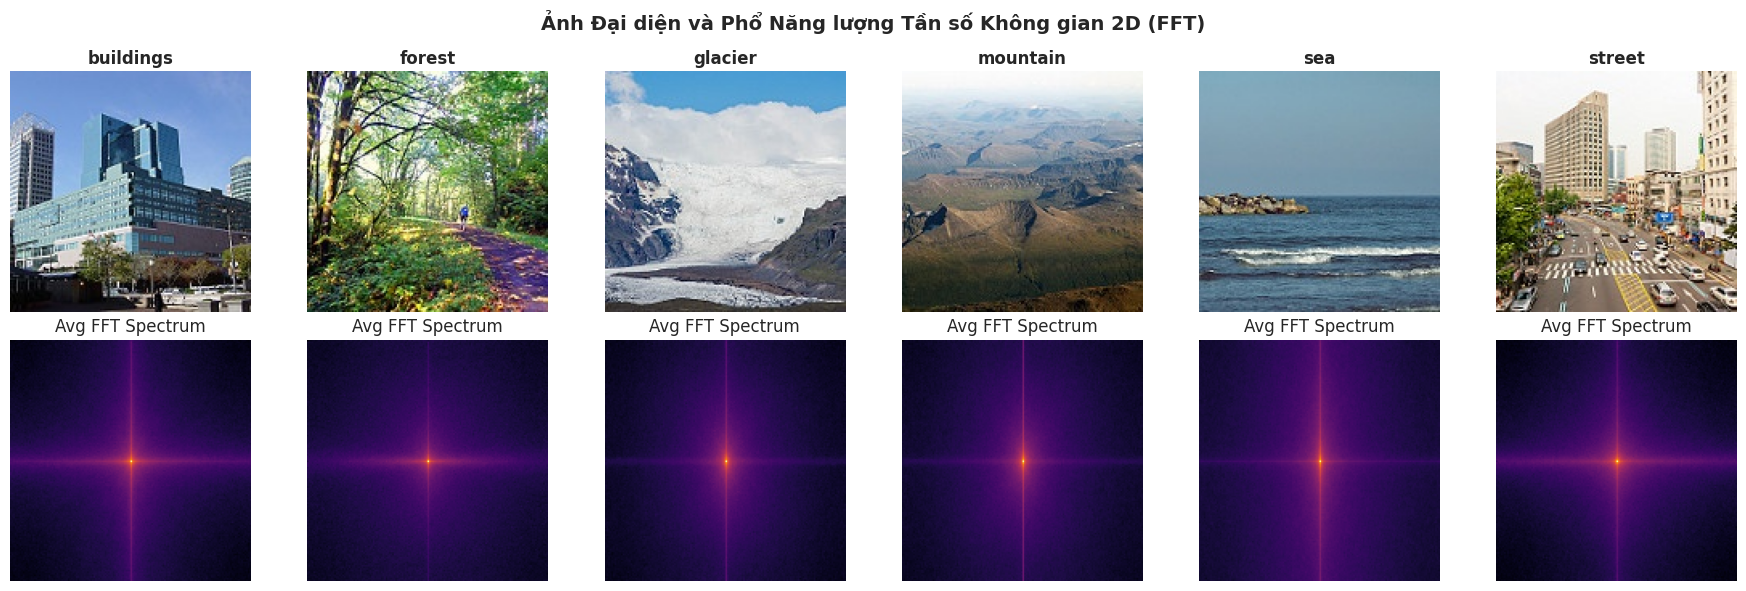

In [12]:
def compute_fft_magnitude(img_path):
    with Image.open(img_path) as img:
        gray = np.array(img.convert('L').resize((150, 150)), dtype=np.float32)
        f = np.fft.fft2(gray)
        fshift = np.fft.fftshift(f)
        magnitude_spectrum = 20 * np.log(np.abs(fshift) + 1e-8)
        return magnitude_spectrum

fig, axes = plt.subplots(2, len(classes), figsize=(18, 6))

for idx, cls_name in enumerate(classes):
    sample_path = df_train_meta[df_train_meta['class'] == cls_name].iloc[0]['filepath']
    
    # Tính phổ FFT trung bình trên 100 ảnh để loại bỏ nhiễu ngẫu nhiên
    paths = df_train_meta[df_train_meta['class'] == cls_name].sample(100, random_state=RANDOM_SEED)['filepath']
    spectra = [compute_fft_magnitude(p) for p in paths]
    avg_spectrum = np.mean(spectra, axis=0)
    
    with Image.open(sample_path) as img:
        axes[0, idx].imshow(img.resize((150, 150)))
        axes[0, idx].set_title(cls_name, fontweight='bold')
        axes[0, idx].axis('off')
        
    im = axes[1, idx].imshow(avg_spectrum, cmap='inferno')
    axes[1, idx].set_title("Avg FFT Spectrum")
    axes[1, idx].axis('off')

plt.suptitle("Ảnh Đại diện và Phổ Năng lượng Tần số Không gian 2D (FFT)", fontsize=14, y=0.98, fontweight='bold')
plt.tight_layout()
plt.show()

**Nhận xét:**
- `forest` có năng lượng phổ tần số phân tán tỏa tròn rất rộng ra các vùng biên, phản ánh mật độ chi tiết dày đặc đa hướng từ các tán lá và cành cây.
- `buildings` và `street` có phổ năng lượng kéo dài theo hình chữ thập (trục ngang và trục dọc), thể hiện rõ các cạnh thẳng vuông góc của kiến trúc nhân tạo.
- `sea` và `glacier` có năng lượng tập trung hầu như hoàn toàn ở tâm điểm tần số thấp, năng lượng suy giảm cực nhanh khi ra vùng biên, minh chứng cho các mảng bề mặt mượt mà.

### 4.3 Phân tích Mật độ Cạnh (Edge Density & Texture Gradient) bằng Toán tử Sobel

Để định lượng sự khác biệt về độ sắc nét và mật độ kết cấu giữa cảnh tự nhiên và cảnh đô thị, nhóm sử dụng toán tử Sobel tính độ lớn gradient không gian $G = \sqrt{G_x^2 + G_y^2}$.

/tmp/ipykernel_6119/630640663.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_edges, x='class', y='edge_density', palette='magma', errorbar='sd', capsize=0.1)


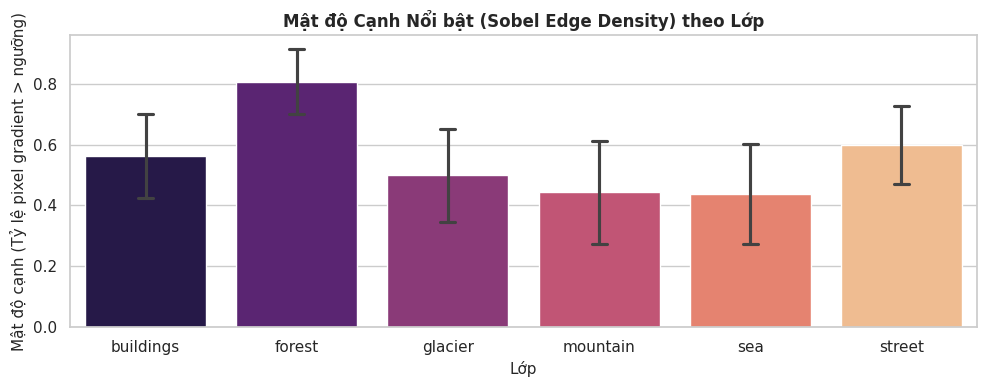

In [13]:
edge_records = []

for cls_name in classes:
    paths = df_train_meta[df_train_meta['class'] == cls_name].sample(
        n=400, random_state=RANDOM_SEED
    )['filepath'].tolist()
    
    for p in paths:
        with Image.open(p) as img:
            gray = np.array(img.convert('L').resize((150, 150)), dtype=np.uint8)
            sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
            sobely = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
            gradient_mag = np.sqrt(sobelx**2 + sobely**2)
            edge_density = np.mean(gradient_mag > 50.0) # Tỷ lệ pixel có gradient lớn
            edge_records.append({'class': cls_name, 'edge_density': edge_density})

df_edges = pd.DataFrame(edge_records)

plt.figure(figsize=(10, 4))
sns.barplot(data=df_edges, x='class', y='edge_density', palette='magma', errorbar='sd', capsize=0.1)
plt.title("Mật độ Cạnh Nổi bật (Sobel Edge Density) theo Lớp", fontweight='bold')
plt.xlabel("Lớp")
plt.ylabel("Mật độ cạnh (Tỷ lệ pixel gradient > ngưỡng)")
plt.tight_layout()
plt.show()

**Nhận xét:**
- `forest` và `buildings` có mật độ cạnh lớn nhất (trung bình > 0.25), cho thấy đây là hai lớp giàu chi tiết vi mô nhất.
- `sea` và `glacier` có mật độ cạnh thấp nhất (< 0.12).
- Khám phá này gợi ý rằng các tầng tích chập sâu (Deep Conv Layers) với receptive field lớn sẽ rất quan trọng để mô hình nắm bắt được ngữ nghĩa toàn cục của `glacier` và `sea`, trong khi các tầng tích chập nông đầu tiên sẽ rất nhạy với đặc trưng vân của `forest` và `buildings`.

## 5. Không gian Đặc trưng và Khảo sát Độ Phân tách (Feature Embedding & Inter-Class Confusion)

### 5.1 Trích xuất Đặc trưng Màu sắc Toàn cục (RGB Color Histograms)

Nhóm trích xuất vector đặc trưng phân bố màu sắc bằng cách tính biểu đồ tần số 8 bins cho mỗi kênh màu RGB (tổng cộng $8 \times 3 = 24$ chiều đặc trưng) trên 1.200 ảnh mẫu ngẫu nhiên từ tập Train.

In [14]:
HIST_SAMPLES_PER_CLASS = 200
hist_features = []
hist_labels = []

for cls_name in classes:
    paths = df_train_meta[df_train_meta['class'] == cls_name].sample(
        n=HIST_SAMPLES_PER_CLASS, random_state=RANDOM_SEED
    )['filepath'].tolist()
    
    for p in paths:
        with Image.open(p) as img:
            arr = np.array(img.convert('RGB'))
            r_hist, _ = np.histogram(arr[:, :, 0], bins=8, range=(0, 256), density=True)
            g_hist, _ = np.histogram(arr[:, :, 1], bins=8, range=(0, 256), density=True)
            b_hist, _ = np.histogram(arr[:, :, 2], bins=8, range=(0, 256), density=True)
            feat = np.concatenate([r_hist, g_hist, b_hist])
            hist_features.append(feat)
            hist_labels.append(cls_name)

X_hist = np.array(hist_features)
print(f"Ma trận đặc trưng màu sắc có kích thước: {X_hist.shape} (N_samples = {len(X_hist)}, D_features = {X_hist.shape[1]})")

Ma trận đặc trưng màu sắc có kích thước: (1200, 24) (N_samples = 1200, D_features = 24)


### 5.2 Giảm Chiều và Trực quan hóa Bằng t-SNE / PCA

Áp dụng t-SNE (t-Distributed Stochastic Neighbor Embedding) để chiếu không gian đặc trưng 24 chiều xuống 2 chiều không gian phẳng nhằm đánh giá khả năng phân cụm tự nhiên dựa trên màu sắc.

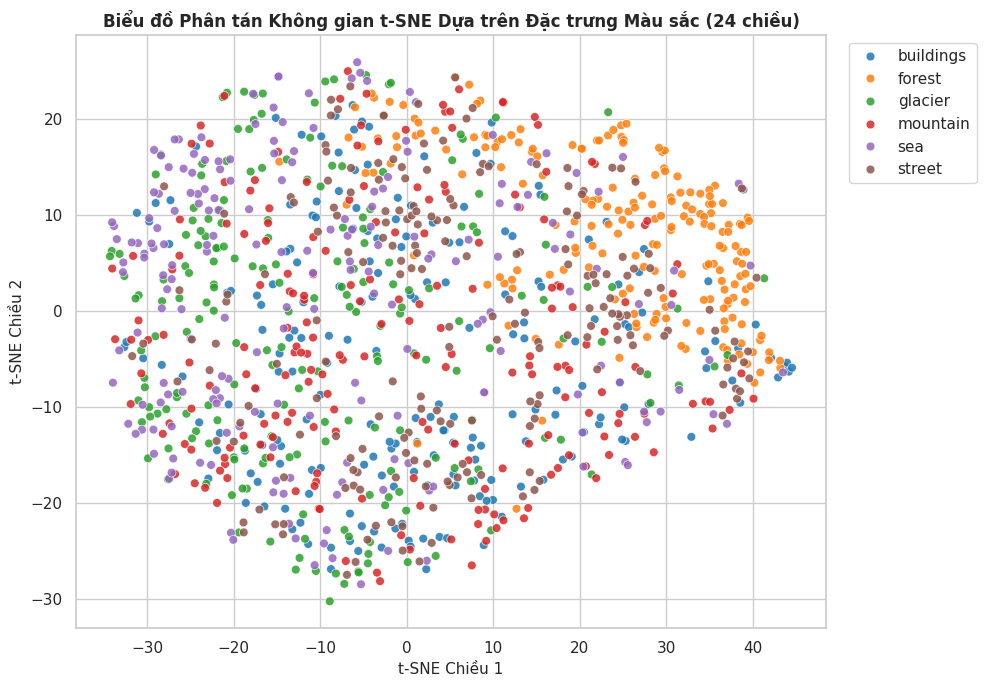

In [15]:
tsne = TSNE(n_components=2, perplexity=35, random_state=RANDOM_SEED, max_iter=1000)
X_tsne = tsne.fit_transform(X_hist)

df_tsne = pd.DataFrame({
    'tSNE-1': X_tsne[:, 0],
    'tSNE-2': X_tsne[:, 1],
    'Class': hist_labels
})

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=df_tsne, 
    x='tSNE-1', 
    y='tSNE-2', 
    hue='Class', 
    palette='tab10', 
    alpha=0.85, 
    s=40
)
plt.title("Biểu đồ Phân tán Không gian t-SNE Dựa trên Đặc trưng Màu sắc (24 chiều)", fontweight='bold')
plt.xlabel("t-SNE Chiều 1")
plt.ylabel("t-SNE Chiều 2")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Quan sát:**
- Lớp `forest` (màu xanh lá) tạo thành một cụm tương đối tách biệt ở phía bên trái biểu đồ, nhờ sắc thái màu xanh đặc trưng.
- Lớp `sea` có xu hướng tách cụm về phía các tông màu xanh lam.
- **Sự chồng lấn nghiêm trọng (Severe Overlap):**
  - Cụm `buildings` và `street` đan xen lẫn nhau rất mạnh ở vùng trung tâm.
  - Cụm `glacier` và `mountain` gần như hòa lẫn hoàn toàn vào nhau.

### 5.3 Khảo sát Các Cặp Lớp Có Nguy cơ Chồng lấn Cao (Domain Overlap & Ambiguity Analysis)

Để chứng minh nguyên nhân vì sao các bộ phân loại tuyến tính hoặc dựa vào màu sắc đơn thuần sẽ thất bại, nhóm trích xuất và hiển thị trực tiếp các trường hợp ảnh thuộc hai cặp dễ nhầm lẫn nhất:
1. `glacier` và `mountain`: Cùng có đá sẫm màu, tuyết trắng và bầu trời.
2. `buildings` và `street`: Cùng thuộc môi trường đô thị với bê tông, ô tô và mặt đường.

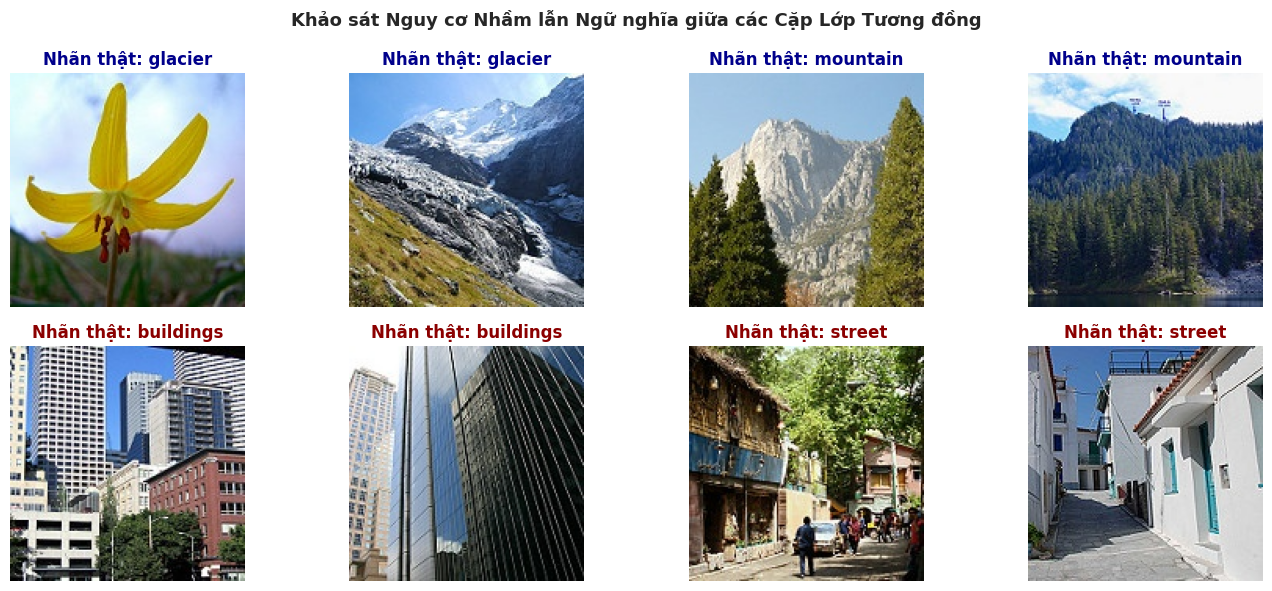

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))

# Lấy 2 ảnh glacier và 2 ảnh mountain
g_paths = df_train_meta[df_train_meta['class'] == 'glacier'].sample(2, random_state=12)['filepath'].tolist()
m_paths = df_train_meta[df_train_meta['class'] == 'mountain'].sample(2, random_state=12)['filepath'].tolist()

for i, p in enumerate(g_paths + m_paths):
    lbl = 'glacier' if i < 2 else 'mountain'
    with Image.open(p) as img:
        axes[0, i].imshow(img)
    axes[0, i].set_title(f"Nhãn thật: {lbl}", color='darkblue', fontweight='bold')
    axes[0, i].axis('off')

# Lấy 2 ảnh buildings và 2 ảnh street
b_paths = df_train_meta[df_train_meta['class'] == 'buildings'].sample(2, random_state=99)['filepath'].tolist()
s_paths = df_train_meta[df_train_meta['class'] == 'street'].sample(2, random_state=99)['filepath'].tolist()

for i, p in enumerate(b_paths + s_paths):
    lbl = 'buildings' if i < 2 else 'street'
    with Image.open(p) as img:
        axes[1, i].imshow(img)
    axes[1, i].set_title(f"Nhãn thật: {lbl}", color='darkred', fontweight='bold')
    axes[1, i].axis('off')

axes[0, 0].set_ylabel("Cặp 1: Núi đá vs Sông băng", fontsize=11, fontweight='bold')
axes[1, 0].set_ylabel("Cặp 2: Tòa nhà vs Đường phố", fontsize=11, fontweight='bold')

plt.suptitle("Khảo sát Nguy cơ Nhầm lẫn Ngữ nghĩa giữa các Cặp Lớp Tương đồng", fontsize=13, y=0.98, fontweight='bold')
plt.tight_layout()
plt.show()

**Nhận xét:**
- Nhìn vào hàng 1, sự khác biệt giữa `glacier` và `mountain` chỉ nằm ở tỷ lệ diện tích tuyết phủ và dạng địa hình (sông băng là dải băng trôi lấp đầy thung lũng, còn núi là đỉnh nhọn đá lộ thiên).
- Nhìn vào hàng 2, trong ảnh `street` luôn có các tòa nhà ở hai bên; trong ảnh `buildings` cũng thường có vỉa hè hoặc lòng đường phía trước.
- **Hệ quả đối với kiến trúc mô hình:** Một mạng CNN đơn giản chỉ dựa vào đặc trưng cục bộ (Low-level features) sẽ rất dễ phân loại sai hai cặp này. Mô hình cần có khả năng nắm bắt **ngữ cảnh không gian toàn cục (Global Spatial Context)** và các đặc trưng ngữ nghĩa cấp cao (High-level semantic features), đòi hỏi sử dụng mạng CNN đủ sâu hoặc Transfer Learning (ResNet-18/34/50, EfficientNet-B0).

## 6. Tổng kết EDA và Đề xuất Kế hoạch Tiền xử lý & Huấn luyện (Action Plan)

### 6.1 Mô phỏng và Đánh giá Chiến lược Tăng cường Dữ liệu (Data Augmentation Simulation)

Dựa trên các phân tích vật lý và không gian ở các phần trước, nhóm thiết lập và kiểm nghiệm trực quan pipeline tăng cường dữ liệu đề xuất:
- `RandomHorizontalFlip(p=0.5)`: Phù hợp tuyệt đối với phong cảnh tự nhiên.
- `RandomResizedCrop(scale=(0.8, 1.0))`: Mô phỏng sự thay đổi tiêu cự và góc chụp mà không làm méo hình.
- `ColorJitter(brightness=0.15, contrast=0.15)`: Tăng độ bền vững trước điều kiện thời tiết và giờ chụp khác nhau trong ngày.

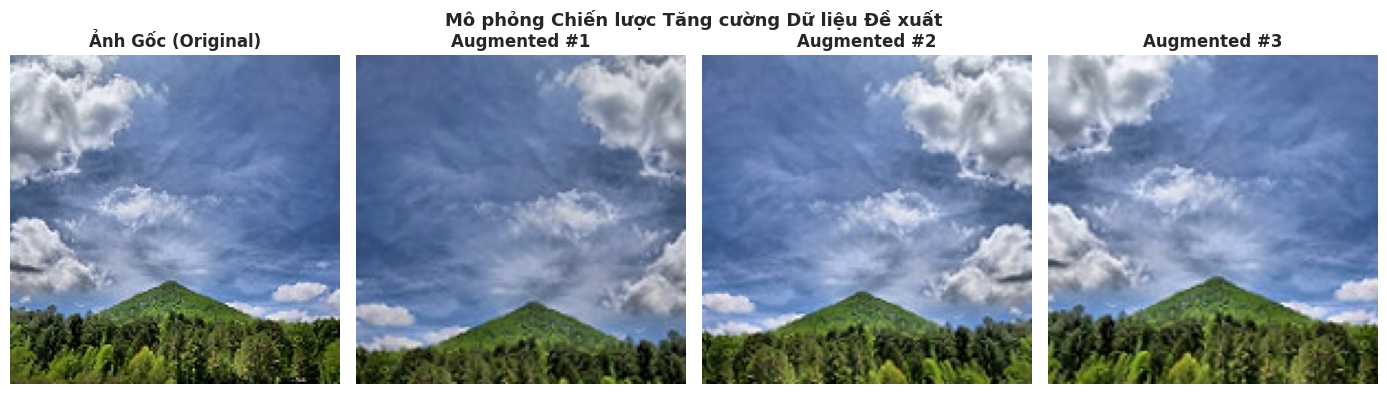

In [17]:
# Thử nghiệm phép biến đổi tăng cường dữ liệu sử dụng thư viện PIL
def apply_simulated_augmentation(img):
    # 1. Random Horizontal Flip (an toàn cho cảnh quan)
    if random.random() > 0.5:
        img = img.transpose(Image.FLIP_LEFT_RIGHT)
        
    # 2. Random Crop & Resize (mô phỏng zoom tiêu cự)
    w, h = img.size
    crop_scale = random.uniform(0.85, 1.0)
    new_w, new_h = int(w * crop_scale), int(h * crop_scale)
    x1 = random.randint(0, w - new_w)
    y1 = random.randint(0, h - new_h)
    img = img.crop((x1, y1, x1 + new_w, y1 + new_h)).resize((150, 150))
    
    # 3. Color Jitter mô phỏng (Brightness)
    enhancer = ImageEnhance.Brightness(img)
    img = enhancer.enhance(random.uniform(0.85, 1.15))
    return img

# Trực quan hóa so sánh ảnh gốc và 3 biến thể sinh ra
demo_path = df_train_meta[df_train_meta['class'] == 'mountain'].iloc[1]['filepath']

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
with Image.open(demo_path) as base_img:
    base_img_resized = base_img.resize((150, 150))
    axes[0].imshow(base_img_resized)
    axes[0].set_title("Ảnh Gốc (Original)", fontweight='bold')
    axes[0].axis('off')
    
    # 3 biến thể tăng cường
    for i in range(1, 4):
        variant = apply_simulated_augmentation(base_img_resized.copy())
        axes[i].imshow(variant)
        axes[i].set_title(f"Augmented #{i}", fontweight='bold')
        axes[i].axis('off')

plt.suptitle("Mô phỏng Chiến lược Tăng cường Dữ liệu Đề xuất", fontsize=13, y=0.98, fontweight='bold')
plt.tight_layout()
plt.show()

**Nhận xét:**
- Các biến thể sau tăng cường dữ liệu giữ nguyên được nhãn ngữ nghĩa của phong cảnh (`mountain`), không bị bóp méo vô lý hay biến đổi màu sắc quá đà.
- Chiến lược này giúp tăng tính đa dạng cho khoảng 14.000 ảnh tập Train và chống hiện tượng quá khớp (Overfitting) hiệu quả.

### 6.2 Bảng Tổng kết Đối chiếu Kết quả EDA và Định hướng Kỹ thuật

Dựa trên toàn bộ kết quả phân tích định lượng và trực quan hóa dữ liệu ở các mục trên, nhóm tổng kết các phát hiện cốt lõi và đưa ra quyết định kỹ thuật tương ứng cho các bước tiền xử lý và xây dựng mô hình tiếp theo:

#### Bảng Đối chiếu Kết quả EDA và Kế hoạch Thực hiện

| Khía cạnh Khảo sát | Phát hiện Cốt lõi từ EDA | Quyết định Tiền xử lý & Huấn luyện (Action Plan) |
| :--- | :--- | :--- |
| **1. Tính toàn vẹn tệp (Integrity)** | 100% tệp ảnh hợp lệ, không có tệp hỏng. Toàn bộ là 3 kênh màu RGB. | Không cần bước lọc bỏ tệp lỗi. Pipeline đọc ảnh trực tiếp qua đường dẫn. |
| **2. Độ phân giải không gian** | Có 48 ảnh Train và 7 ảnh Test không phải kích thước 150x150. | Bắt buộc áp dụng `transforms.Resize((150, 150))` để tránh lỗi runtime khi gom mini-batch. |
| **3. Cân bằng nhãn (Class Balance)** | 6 lớp có phân phối rất đồng đều (~16.6% mỗi lớp, tỷ lệ min/max = 1.14). | Không cần class-weights hay Focal Loss; sử dụng **CrossEntropyLoss** tiêu chuẩn và độ đo **Accuracy / Macro F1**. |
| **4. Phân phối kênh màu (RGB)** | Kênh Green và Blue chiếm ưu thế do đặc thù cảnh tự nhiên ngoài trời. | Nếu huấn luyện mô hình từ đầu, chuẩn hóa theo dataset mean/std; nếu dùng Pretrained Backbone, giữ nguyên chuẩn ImageNet. |
| **5. Định kiến không gian (Priors)** | Bố cục đường chân trời nằm ngang, bầu trời ở nửa trên khung hình. | **Chỉ dùng** `RandomHorizontalFlip`; **loại trừ hoàn toàn** `RandomVerticalFlip` để không vi phạm quy luật trọng lực. |
| **6. Đặc trưng tần số & Độ tương phản** | Rừng và Tòa nhà có tần số cao và cạnh sắc nét; Biển và Băng tuyết trơn mượt. | Mô hình cần đủ độ sâu để dung hòa cả đặc trưng kết cấu tần số cao lẫn bố cục không gian tần số thấp. |
| **7. Độ chồng lấn nhãn (Confusion)** | Chồng lấn nặng giữa `glacier` - `mountain` và `buildings` - `street`. | Sử dụng mạng CNN sâu có năng lực biểu diễn cao (ResNet-18/34/50 hoặc EfficientNet); theo dõi ma trận nhầm lẫn (Confusion Matrix). |

---
**Kết luận:** Quá trình EDA đã làm sáng tỏ cấu trúc hình học, phân phối màu sắc và các rủi ro ngữ nghĩa tiềm ẩn của bộ dữ liệu Intel Image Classification, cung cấp cơ sở khoa học vững chắc cho việc thiết kế pipeline huấn luyện tối ưu ở giai đoạn tiếp theo.